CS 020 midterm Report

Prahalad Kangeyan

CS 020

Dr. Shaw

#I.Introduction

link to source: https://www.kaggle.com/datasets/shariful07/student-mental-health/discussion?sort=hotness

What is it about :
The data is about self reported mental health questionaire from (International Islamic University Malaysia) it is taken from 101 students

What motivated me to use it : I wanted to use it becuase it seemed like a usable dataset to run machine learning models on to predict mental health outcomes and risks

Questions I am trying to answer with this : Can I accurately predict depression with self reported data with features like cgpa, year of study, marital status, etc.

#II.Setup importing libraries

In [ ]:
from datascience import*
import matplotlib as plt
%matplotlib inline
import numpy as np

In [ ]:
from google.colab import files
uploaded = files.upload()

Saving Student Mental health.csv to Student Mental health.csv


In [ ]:
student_data = Table.read_table("Student Mental health.csv")

#III.Dataset cleaning


In [ ]:
student_data.show(10)

Timestamp,Choose your gender,Age,What is your course?,Your current year of Study,What is your CGPA?,Marital status,Do you have Depression?,Do you have Anxiety?,Do you have Panic attack?,Did you seek any specialist for a treatment?
8/7/2020 12:02,Female,18,Engineering,year 1,3.00 - 3.49,No,Yes,No,Yes,No
8/7/2020 12:04,Male,21,Islamic education,year 2,3.00 - 3.49,No,No,Yes,No,No
8/7/2020 12:05,Male,19,BIT,Year 1,3.00 - 3.49,No,Yes,Yes,Yes,No
8/7/2020 12:06,Female,22,Laws,year 3,3.00 - 3.49,Yes,Yes,No,No,No
8/7/2020 12:13,Male,23,Mathemathics,year 4,3.00 - 3.49,No,No,No,No,No
8/7/2020 12:31,Male,19,Engineering,Year 2,3.50 - 4.00,No,No,No,Yes,No
8/7/2020 12:32,Female,23,Pendidikan islam,year 2,3.50 - 4.00,Yes,Yes,No,Yes,No
8/7/2020 12:33,Female,18,BCS,year 1,3.50 - 4.00,No,No,Yes,No,No
8/7/2020 12:35,Female,19,Human Resources,Year 2,2.50 - 2.99,No,No,No,No,No
8/7/2020 12:39,Male,18,Irkhs,year 1,3.50 - 4.00,No,No,Yes,Yes,No


Selecting relevant rows as rows like timestamp is not as useful

**Dataset Cleaning**

code for changing yes or no's into boolean values

In [ ]:
def choiceToBoolean(entry):
	if entry == "Yes":
		return 1
	elif entry == "No":
		return 0

 In the following steps I updated student_data with *student_data_new*

In [ ]:
student_data_new = student_data.with_column("Depression boolean", student_data.apply(choiceToBoolean, "Do you have Depression?"))
student_data_new  = student_data_new.with_column("Panic Attack Boolean", student_data.apply(choiceToBoolean, "Do you have Panic attack?"))
student_data_new  = student_data_new.with_column("Anxiety Boolean", student_data.apply(choiceToBoolean, "Do you have Anxiety?"))
student_data_new  = student_data_new.with_column("Sought specialist Boolean", student_data.apply(choiceToBoolean, "Did you seek any specialist for a treatment?"))
student_data_new  = student_data_new.with_column("Marital Boolean", student_data.apply(choiceToBoolean, "Marital status"))

In [ ]:
student_data_new

Timestamp,Choose your gender,Age,What is your course?,Your current year of Study,What is your CGPA?,Marital status,Do you have Depression?,Do you have Anxiety?,Do you have Panic attack?,Did you seek any specialist for a treatment?,Depression boolean,Panic Attack Boolean,Anxiety Boolean,Sought specialist Boolean,Marital Boolean
8/7/2020 12:02,Female,18,Engineering,year 1,3.00 - 3.49,No,Yes,No,Yes,No,1,1,0,0,0
8/7/2020 12:04,Male,21,Islamic education,year 2,3.00 - 3.49,No,No,Yes,No,No,0,0,1,0,0
8/7/2020 12:05,Male,19,BIT,Year 1,3.00 - 3.49,No,Yes,Yes,Yes,No,1,1,1,0,0
8/7/2020 12:06,Female,22,Laws,year 3,3.00 - 3.49,Yes,Yes,No,No,No,1,0,0,0,1
8/7/2020 12:13,Male,23,Mathemathics,year 4,3.00 - 3.49,No,No,No,No,No,0,0,0,0,0
8/7/2020 12:31,Male,19,Engineering,Year 2,3.50 - 4.00,No,No,No,Yes,No,0,1,0,0,0
8/7/2020 12:32,Female,23,Pendidikan islam,year 2,3.50 - 4.00,Yes,Yes,No,Yes,No,1,1,0,0,1
8/7/2020 12:33,Female,18,BCS,year 1,3.50 - 4.00,No,No,Yes,No,No,0,0,1,0,0
8/7/2020 12:35,Female,19,Human Resources,Year 2,2.50 - 2.99,No,No,No,No,No,0,0,0,0,0
8/7/2020 12:39,Male,18,Irkhs,year 1,3.50 - 4.00,No,No,Yes,Yes,No,0,1,1,0,0


In [ ]:
groupedDepressionData = student_data_new.group("Depression boolean")

In [ ]:
groupedDepressionData

Depression boolean,count
0,66
1,35


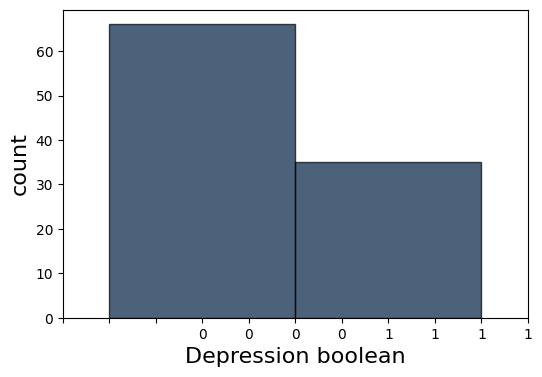

In [ ]:
groupedDepressionData.bar("Depression boolean")


In [ ]:
year_column = student_data_new.column("Your current year of Study")
year_column

array(['year 1', 'year 2', 'Year 1', 'year 3', 'year 4', 'Year 2',
       'year 2', 'year 1', 'Year 2', 'year 1', 'year 1', 'Year 3',
       'year 1', 'year 1', 'Year 2', 'Year 3', 'year 3', 'year 4',
       'Year 2', 'year 2', 'year 1', 'Year 2', 'year 1', 'year 1',
       'Year 3', 'year 1', 'year 1', 'Year 2', 'Year 3', 'year 4',
       'Year 2', 'year 2', 'year 1', 'Year 2', 'year 1', 'year 1',
       'Year 3', 'year 1', 'year 1', 'Year 2', 'Year 3', 'year 4',
       'year 2', 'year 1', 'year 2', 'year 1', 'year 1', 'year 4',
       'year 2', 'year 3', 'year 1', 'year 2', 'year 3', 'year 3',
       'year 1', 'year 1', 'Year 3', 'Year 3', 'year 1', 'year 1',
       'Year 3', 'year 1', 'Year 1', 'year 1', 'year 1', 'year 1',
       'Year 3', 'Year 3', 'year 1', 'year 4', 'year 1', 'Year 3',
       'Year 3', 'year 1', 'Year 3', 'year 1', 'year 1', 'Year 2',
       'Year 3', 'year 4', 'Year 2', 'year 2', 'year 1', 'Year 2',
       'year 1', 'year 1', 'Year 3', 'year 1', 'year 1', 'Year

Get last year from the data by just taking the last index and storing in into a new array

In [ ]:
#new empty array for storing just the numbers
yearNumbers = np.array([])


In [ ]:
for year in year_column:
    yearNumbers = np.append(yearNumbers, year[-1])

In [ ]:
yearNumbers

array(['1', '2', '1', '3', '4', '2', '2', '1', '2', '1', '1', '3', '1',
       '1', '2', '3', '3', '4', '2', '2', '1', '2', '1', '1', '3', '1',
       '1', '2', '3', '4', '2', '2', '1', '2', '1', '1', '3', '1', '1',
       '2', '3', '4', '2', '1', '2', '1', '1', '4', '2', '3', '1', '2',
       '3', '3', '1', '1', '3', '3', '1', '1', '3', '1', '1', '1', '1',
       '1', '3', '3', '1', '4', '1', '3', '3', '1', '3', '1', '1', '2',
       '3', '4', '2', '2', '1', '2', '1', '1', '3', '1', '1', '2', '3',
       '2', '2', '1', '3', '1', '1', '2', '3', '4', '2'],
      dtype='<U32')

entering this column into out dataset

In [ ]:
student_data_new  = student_data_new.with_column("Year values", yearNumbers)

In [ ]:
student_data_new

Timestamp,Choose your gender,Age,What is your course?,Your current year of Study,What is your CGPA?,Marital status,Do you have Depression?,Do you have Anxiety?,Do you have Panic attack?,Did you seek any specialist for a treatment?,Depression boolean,Panic Attack Boolean,Anxiety Boolean,Sought specialist Boolean,Marital Boolean,Year values
8/7/2020 12:02,Female,18,Engineering,year 1,3.00 - 3.49,No,Yes,No,Yes,No,1,1,0,0,0,1
8/7/2020 12:04,Male,21,Islamic education,year 2,3.00 - 3.49,No,No,Yes,No,No,0,0,1,0,0,2
8/7/2020 12:05,Male,19,BIT,Year 1,3.00 - 3.49,No,Yes,Yes,Yes,No,1,1,1,0,0,1
8/7/2020 12:06,Female,22,Laws,year 3,3.00 - 3.49,Yes,Yes,No,No,No,1,0,0,0,1,3
8/7/2020 12:13,Male,23,Mathemathics,year 4,3.00 - 3.49,No,No,No,No,No,0,0,0,0,0,4
8/7/2020 12:31,Male,19,Engineering,Year 2,3.50 - 4.00,No,No,No,Yes,No,0,1,0,0,0,2
8/7/2020 12:32,Female,23,Pendidikan islam,year 2,3.50 - 4.00,Yes,Yes,No,Yes,No,1,1,0,0,1,2
8/7/2020 12:33,Female,18,BCS,year 1,3.50 - 4.00,No,No,Yes,No,No,0,0,1,0,0,1
8/7/2020 12:35,Female,19,Human Resources,Year 2,2.50 - 2.99,No,No,No,No,No,0,0,0,0,0,2
8/7/2020 12:39,Male,18,Irkhs,year 1,3.50 - 4.00,No,No,Yes,Yes,No,0,1,1,0,0,1


In [ ]:
student_data_new = student_data_new.select("Choose your gender","Age", "Your current year of Study", "What is your CGPA?", "Depression boolean", "Sought specialist Boolean", "Panic Attack Boolean", "Anxiety Boolean", "Marital Boolean")

chosen relevant and usable columns

In [ ]:
student_data_new

Choose your gender,Age,Your current year of Study,What is your CGPA?,Depression boolean,Sought specialist Boolean,Panic Attack Boolean,Anxiety Boolean,Marital Boolean
Female,18,year 1,3.00 - 3.49,1,0,1,0,0
Male,21,year 2,3.00 - 3.49,0,0,0,1,0
Male,19,Year 1,3.00 - 3.49,1,0,1,1,0
Female,22,year 3,3.00 - 3.49,1,0,0,0,1
Male,23,year 4,3.00 - 3.49,0,0,0,0,0
Male,19,Year 2,3.50 - 4.00,0,0,1,0,0
Female,23,year 2,3.50 - 4.00,1,0,1,0,1
Female,18,year 1,3.50 - 4.00,0,0,0,1,0
Female,19,Year 2,2.50 - 2.99,0,0,0,0,0
Male,18,year 1,3.50 - 4.00,0,0,1,1,0


Turning years into only their values

In [ ]:
year_column = student_data_new.column("Your current year of Study")
yearNumbers = np.array([])
for year in year_column:
    yearNumbers = np.append(yearNumbers, int(year[-1]))


In [ ]:
student_data_new  = student_data_new.with_column("Year", yearNumbers)

In [ ]:
student_data_new = student_data_new.drop("Your current year of Study")

In [ ]:
student_data_new.show(91)

Choose your gender,Age,What is your CGPA?,Depression boolean,Sought specialist Boolean,Panic Attack Boolean,Anxiety Boolean,Marital Boolean,Year
Female,18,3.00 - 3.49,1,0,1,0,0,1
Male,21,3.00 - 3.49,0,0,0,1,0,2
Male,19,3.00 - 3.49,1,0,1,1,0,1
Female,22,3.00 - 3.49,1,0,0,0,1,3
Male,23,3.00 - 3.49,0,0,0,0,0,4
Male,19,3.50 - 4.00,0,0,1,0,0,2
Female,23,3.50 - 4.00,1,0,1,0,1,2
Female,18,3.50 - 4.00,0,0,0,1,0,1
Female,19,2.50 - 2.99,0,0,0,0,0,2
Male,18,3.50 - 4.00,0,0,1,1,0,1


Used very similar logic from my yes/no to boolean function

In [ ]:
def genderToBoolean(entry):
	if entry == "Female":
		return 1
	elif entry == "Male":
		return 0

In [ ]:
student_data_new  = student_data_new.with_column("gender Boolean", student_data.apply(genderToBoolean, "Choose your gender"))

In [ ]:
student_data_new = student_data_new.drop("Choose your gender")

removing previous gender column that is categorical

In [ ]:
student_data_new.show(91)

Age,What is your CGPA?,Depression boolean,Sought specialist Boolean,Panic Attack Boolean,Anxiety Boolean,Marital Boolean,Year,gender Boolean
18,3.00 - 3.49,1,0,1,0,0,1,1
21,3.00 - 3.49,0,0,0,1,0,2,0
19,3.00 - 3.49,1,0,1,1,0,1,0
22,3.00 - 3.49,1,0,0,0,1,3,1
23,3.00 - 3.49,0,0,0,0,0,4,0
19,3.50 - 4.00,0,0,1,0,0,2,0
23,3.50 - 4.00,1,0,1,0,1,2,1
18,3.50 - 4.00,0,0,0,1,0,1,1
19,2.50 - 2.99,0,0,0,0,0,2,1
18,3.50 - 4.00,0,0,1,1,0,1,0


Made a function for cgpa to booleen

In [ ]:
def cgpaToNumber(entry):
    if entry == "3.50 - 4.00":
        return 4
    elif entry == "3.00 - 3.49":
        return 3
    elif entry == "2.50 - 2.99":
        return 2
    elif entry == "2.00 - 2.49":
        return 1
    elif entry == "0 - 1.99":
        return 0
    else:
      #one of the values contains an invalid no so this is my solution for that
        return 2


Applying this function to my column

In [ ]:
student_data_new  = student_data_new.with_column("cgpa", student_data.apply(cgpaToNumber, "What is your CGPA?"))

In [ ]:
student_data_new = student_data_new.drop("What is your CGPA?")

In [ ]:
student_data_new.group("cgpa").sort("cgpa")

cgpa,count
0,4
1,2
2,5
3,43
4,47


#IV.EDA

In [ ]:
student_data_new.show(10)

Age,Depression boolean,Sought specialist Boolean,Panic Attack Boolean,Anxiety Boolean,Marital Boolean,Year,gender Boolean,cgpa
18,1,0,1,0,0,1,1,3
21,0,0,0,1,0,2,0,3
19,1,0,1,1,0,1,0,3
22,1,0,0,0,1,3,1,3
23,0,0,0,0,0,4,0,3
19,0,0,1,0,0,2,0,4
23,1,0,1,0,1,2,1,2
18,0,0,0,1,0,1,1,4
19,0,0,0,0,0,2,1,2
18,0,0,1,1,0,1,0,4


##Question1: Is there a relationship between depression and anxiety?

Going to do a correlation coefficient according to chapter 15.1 in the data 8 inferential thinking textbook

In [ ]:
type(student_data_new.column("Depression boolean").item(0))

int

In [ ]:
student_data_new.group("Depression boolean", np.mean)

Depression boolean,Age mean,Sought specialist Boolean mean,Panic Attack Boolean mean,Anxiety Boolean mean,Marital Boolean mean,Year mean,gender Boolean mean,cgpa mean
0,nan,0,0.242424,0.242424,0,1.98485,0.69697,3.27273
1,20.2857,0.171429,0.485714,0.514286,0.457143,1.94286,0.828571,3.22857


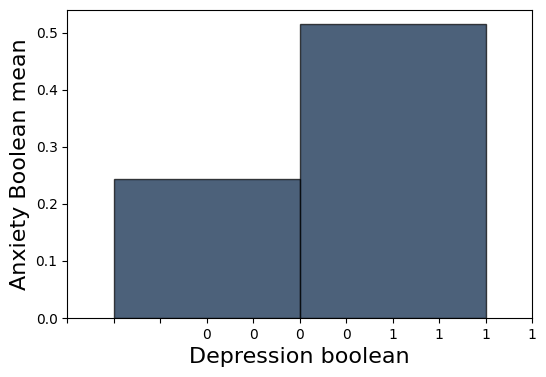

In [ ]:
grouped_data = student_data_new.group("Depression boolean", np.mean).select("Depression boolean","Anxiety Boolean mean")
grouped_data.bar("Depression boolean")

The 0 in this represents those who don't have depression while the 1 represents those who do have depression

This shows that 24% of people without depression had anxiety while 51% percent of people who had depression had anxiety as well

I used a bar chart here to show the difference between the two groups as a scatter chart or a plot would not work here as these are binary values.

 I would also like to do a correlation coefficient using

Conclusion to question: There is a positve correlation between students who report depression and those who report anxiety shown by the higher proportion of people who experienced depression and anixety compared to those who did not experience depression and experienced anxiety

This conclusion did not suprise me as I had heard before that depression and anixety are comorbid disorders.

##Question 2: Do older students experience more self-reported depression

I plan to use a histrogram with this because it can help me compare distributions. So I will make to histograms with age in mind

In [ ]:
type(student_data_new.column(0).item(0))

float

Histogram for those with depression

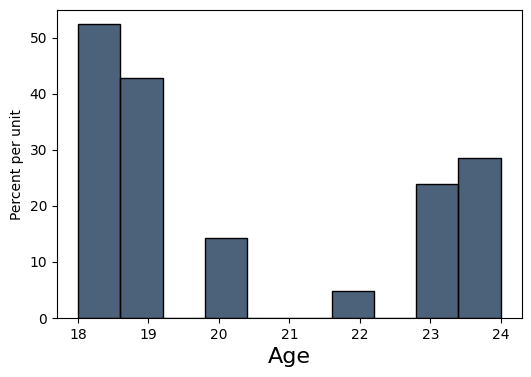

In [ ]:
student_data_new.where('Depression boolean', 1).hist('Age')

Histogram for those without depression

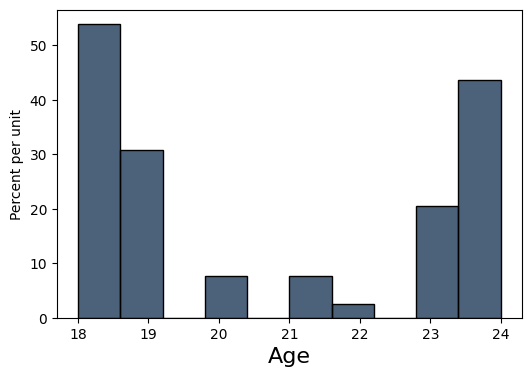

In [ ]:
student_data_new.where('Depression boolean', 0).hist('Age')

Doing an overlay using inferential thinking 7.3 chapter overlaid graphs but modifying it for hist

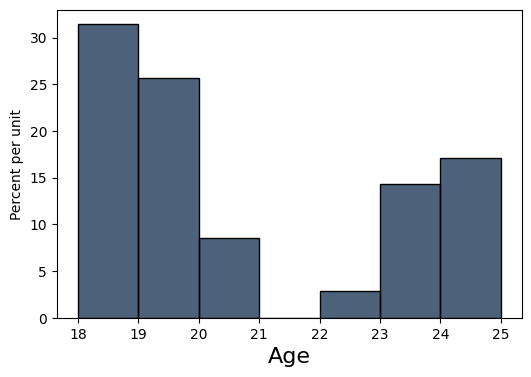

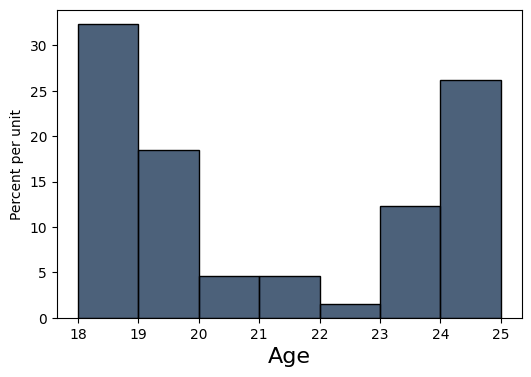

In [ ]:
student_data_new.where('Depression boolean', 1).hist('Age', bins=np.arange(18,26,1))
student_data_new.where('Depression boolean', 0).hist('Age', bins=np.arange(18,26,1),overlay=True)

overlay needs a categorical thing to differentiate so I'm making a new column where I can separate those who have dperession and those who don't have depression

In [ ]:
one_group = student_data_new.where('Depression boolean', 1).with_column("Group", "has depression")
two_group = student_data_new.where('Depression boolean', 0).with_column("Group", "no depression")

In [ ]:
grouped = one_group.append(two_group)

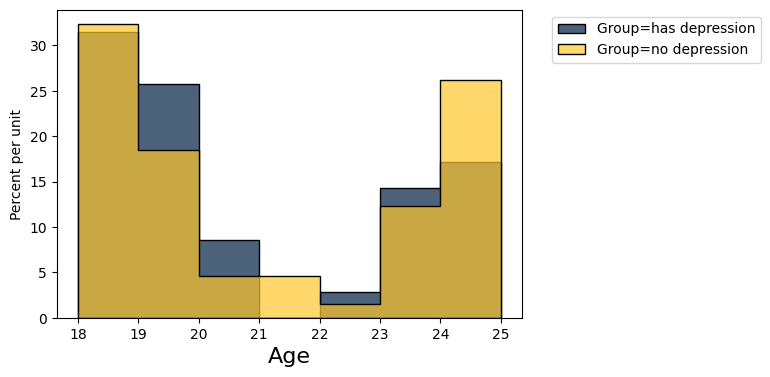

In [ ]:
grouped.hist('Age', group='Group', bins=np.arange(18,26,1))

Analysis of overlaid histogram: This shows that the grouping shows that there is not a big difference between most age years and that being around the age of 24-25 could mean even a lower risk of depression.

Conclusion to question: Older students do not experience more depression. as shown by the graph as the overlay does nnot show significant differences but in some cases it shows that from age 18 expreinced significantly more depression compared to the older ages. Which may show that younger students experience more depression, except for the age 23

In [ ]:
student_data_new.where('Sought specialist Boolean', 1).show()

Age,Depression boolean,Sought specialist Boolean,Panic Attack Boolean,Anxiety Boolean,Marital Boolean,Year,gender Boolean,cgpa
24,1,1,1,1,1,3,1,4
18,1,1,0,1,1,2,0,4
24,1,1,1,0,1,2,1,2
23,1,1,1,0,1,1,1,2
19,1,1,1,0,0,1,1,4
18,1,1,0,1,0,1,1,4


##Question 3: Does self-reported depression correlate with a lowered gpa

In [ ]:
questionThree = student_data_new.group("Depression boolean", np.mean)

In [ ]:
def depression_label(entry):
  if entry == 0:
    return "No depression"
  elif entry == 1:
    return "Depression"

In [ ]:
questionThreeLabeled = student_data_new.with_column("Depression", student_data_new.apply(depression_label, "Depression boolean"))
mean_cgpa = questionThreeLabeled.group("Depression", np.mean)
mean_cgpa

Depression,Age mean,Depression boolean mean,Sought specialist Boolean mean,Panic Attack Boolean mean,Anxiety Boolean mean,Marital Boolean mean,Year mean,gender Boolean mean,cgpa mean
Depression,20.2857,1,0.171429,0.485714,0.514286,0.457143,1.94286,0.828571,3.22857
No depression,nan,0,0,0.242424,0.242424,0,1.98485,0.69697,3.27273


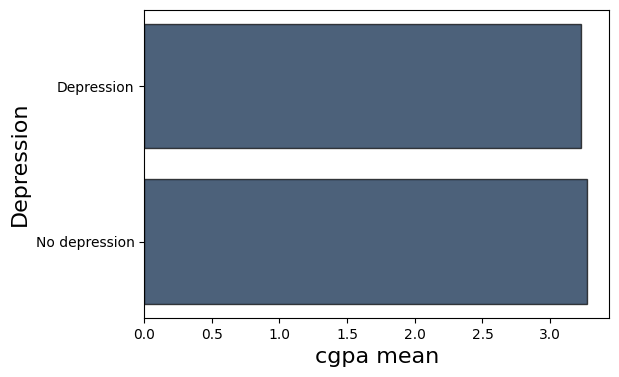

In [ ]:
mean_cgpa.select("Depression", "cgpa mean").barh("Depression")

Bar graph analysis: Thee group with depression earned a gpa of 3.22857 while the group without depression earned on average of 3.27273

Conclusion to question: This shows that there is barely a difference of GPA and that there is not enough evidence to support the idea that depression correlates with a lower gpa

##Question4: Does gender relate to differing depression




In [ ]:
student_data_new.show(10)

Age,Depression boolean,Sought specialist Boolean,Panic Attack Boolean,Anxiety Boolean,Marital Boolean,Year,gender Boolean,cgpa
18,1,0,1,0,0,1,1,3
21,0,0,0,1,0,2,0,3
19,1,0,1,1,0,1,0,3
22,1,0,0,0,1,3,1,3
23,0,0,0,0,0,4,0,3
19,0,0,1,0,0,2,0,4
23,1,0,1,0,1,2,1,2
18,0,0,0,1,0,1,1,4
19,0,0,0,0,0,2,1,2
18,0,0,1,1,0,1,0,4


In [ ]:
gender_grouping = student_data_new.group("gender Boolean", np.mean)
gender_grouping

gender Boolean,Age mean,Depression boolean mean,Sought specialist Boolean mean,Panic Attack Boolean mean,Anxiety Boolean mean,Marital Boolean mean,Year mean,cgpa mean
0,nan,0.230769,0.0384615,0.307692,0.384615,0.115385,1.84615,3.03846
1,20.5333,0.386667,0.0666667,0.333333,0.32,0.173333,2.01333,3.33333


Selecting what I need

In [ ]:
new_gender_group = gender_grouping.select("gender Boolean", "Depression boolean mean")
new_gender_group

gender Boolean,Depression boolean mean
0,0.230769
1,0.386667


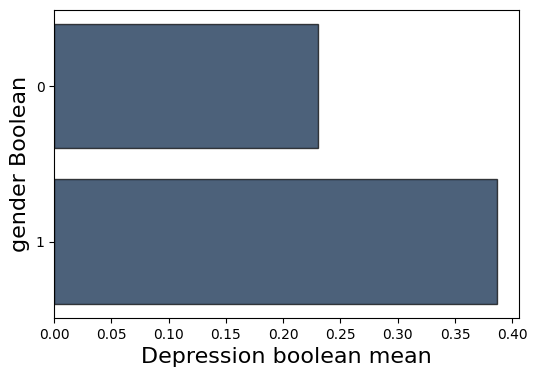

In [ ]:
new_gender_group.barh("gender Boolean")

Analysis of bar graph: The left bar graph (0) represents male and the right bar graph represents female(1). by the graph males represent about 0.24 so 24% of males experience depression and .38 so 38% percent of all females report depression.

Conclusion to the Question: Females seem to experience almost twice the amount of depression compared to males. This is a significant dfifference. This did surprise me I did not think it would be so much higher. This makes me want to go in deeper and figure out why. I thought that since woman were traditionally considered to have better social support groups and better emotional intelligence they would fare better.

##Question5: Do panic attacks increase chances of experiencing depression

In [ ]:
Panic_attack_grouping = student_data_new.group("Panic Attack Boolean", np.mean)
Panic_attack_grouping

Panic Attack Boolean,Age mean,Depression boolean mean,Sought specialist Boolean mean,Anxiety Boolean mean,Marital Boolean mean,Year mean,gender Boolean mean,cgpa mean
0,nan,0.264706,0.0294118,0.308824,0.0882353,1.98529,0.735294,3.25
1,20.7273,0.515152,0.121212,0.393939,0.30303,1.93939,0.757576,3.27273


In [ ]:
Panic_attack_grouping_new = Panic_attack_grouping.select("Panic Attack Boolean", "Depression boolean mean")
Panic_attack_grouping_new

Panic Attack Boolean,Depression boolean mean
0,0.264706
1,0.515152


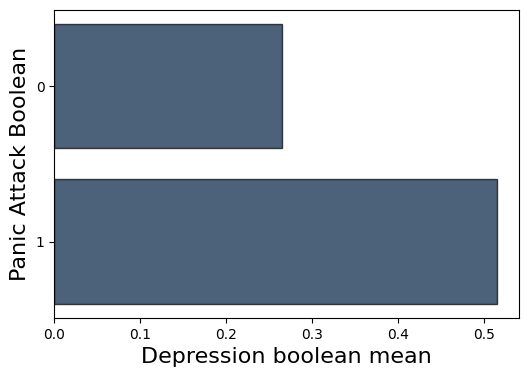

In [ ]:
Panic_attack_grouping_new.select("Panic Attack Boolean", "Depression boolean mean").barh("Panic Attack Boolean")

Analysis of graph and data: The people who did not have a panic attack but experienced depression was around 26.4% but the people who experiences panic attack and depression was 51%.

Conclusion of the question: The people who experiences panic attacks were also more likely to experience depression almost double. However this data looks very similar to my first question which leads to my next question

##Question6: Do people who experience panic Attacks also experience anxiety

In [ ]:
anxiety_and_panic_attack = student_data_new.group("Panic Attack Boolean", np.mean)
anxiety_and_panic_attack

Panic Attack Boolean,Age mean,Depression boolean mean,Sought specialist Boolean mean,Anxiety Boolean mean,Marital Boolean mean,Year mean,gender Boolean mean,cgpa mean
0,nan,0.264706,0.0294118,0.308824,0.0882353,1.98529,0.735294,3.25
1,20.7273,0.515152,0.121212,0.393939,0.30303,1.93939,0.757576,3.27273


In [ ]:
anxiety_and_panic_attack_new = anxiety_and_panic_attack.select("Panic Attack Boolean", "Anxiety Boolean mean")
anxiety_and_panic_attack_new

Panic Attack Boolean,Anxiety Boolean mean
0,0.308824
1,0.393939


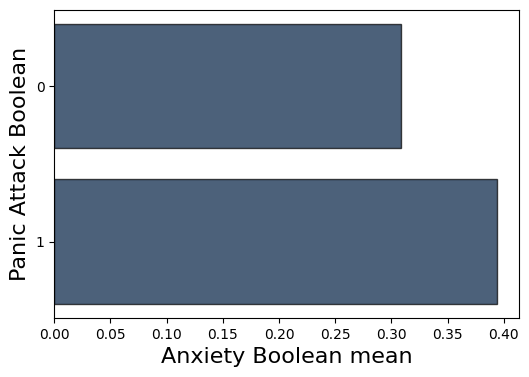

In [ ]:
anxiety_and_panic_attack_new.select("Panic Attack Boolean", "Anxiety Boolean mean").barh("Panic Attack Boolean")

Analysis of the graph: no panic attack and anxiety is 31% while students with panic attacks and anxiety is 39%

Conclusion to the question: Experiencing panic attacks leads to a slightly higher likelihood of also experiencing anixety

##Question7: Does depression rate increase by year of study

A line plot seems appropriate to show the difference throughout the years in depression

In [ ]:
depression_yearly = student_data_new.group("Year", np.mean)
depression_yearly

Year,Age mean,Depression boolean mean,Sought specialist Boolean mean,Panic Attack Boolean mean,Anxiety Boolean mean,Marital Boolean mean,gender Boolean mean,cgpa mean
1,nan,0.325581,0.0697674,0.325581,0.325581,0.0232558,0.767442,3.30233
2,20.2308,0.384615,0.0769231,0.307692,0.384615,0.269231,0.576923,3.15385
3,21.2083,0.416667,0.0416667,0.416667,0.333333,0.291667,0.833333,3.16667
4,22,0.125,0,0.125,0.25,0.125,0.875,3.625


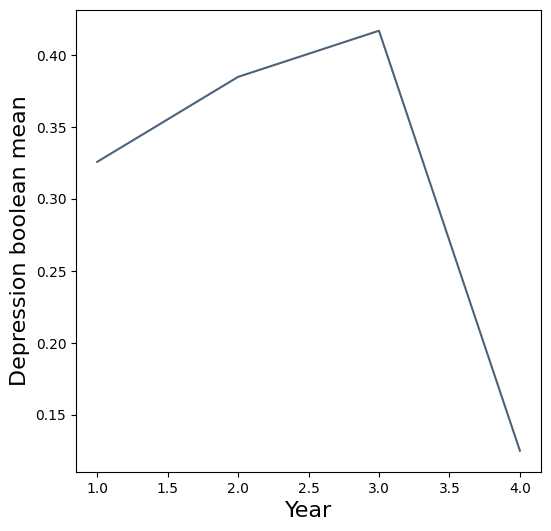

In [ ]:
depression_yearly.plot("Year", "Depression boolean mean")

Analysis of graph: Depression was ataround .33 at the first year and slowly increased and reache da peak at the 3rd year. But at the last year it sharply fell

Conclusion to the Question: The answer to the question is kind of true as there is an increase of depression generally until year three but year 4's depression average seems to suggest a significant dropoff

#Taking out 11 rows

In [ ]:

train = student_data_new.take(np.arange(0,80))

#not used for train or test.
keepForEnd = student_data_new.take(np.arange(80,91))

#Machine Learning

Splitting the training and test set

Test set: I need to keep a test set so that I can assess the accuracy of the model

Training set:The training set is used to train the actual model

X is my features for training the model

and Y is my targer for if they have depression?     

data must be in numpy arrays for scikit learn to accept it

Using the datacamp pipeline


Pipline shown in this link https://www.datacamp.com/tutorial/decision-tree-classification-python

Importing libraries

Loading data

Feature selection

Splitting Data into training at test set

Building the decision tree model

Evaluating the model



##importing libraries
---

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn import metrics
from sklearn.model_selection import *

##Loading and preparing data
---

In [ ]:
age = train.column("Age")
gender = train.column("gender Boolean")
year = train.column("Year")
specialist = train.column("Sought specialist Boolean")
panic_attack = train.column("Panic Attack Boolean")
anxiety = train.column("Anxiety Boolean")
marital = train.column("Marital Boolean")
gpa = train.column("cgpa")


## Feature selection
---

In [ ]:
X = np.column_stack((age, gender, year, specialist, panic_attack, anxiety, marital, gpa))
y = train.column("Depression boolean")

11 row test slice

In [ ]:
X.shape


(80, 8)

In [ ]:
y.shape

(80,)

Shape is for checking whether there are the right number or rows and columns

For y I only have the rows because it is the target and these are all the rows of the depression target

##Splitting into training and test set

---

To use the sklearn decision tree classifier I need to make a x_train and x_test to use to predict a y

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state =17, test_size= 0.2, stratify = y)

the test_size = 0.2  means 20 percent

## Building decision tree model
---

I copied this code directly from the datacamp guide for the decision tree classifier listed above

In [ ]:
# Create Decision Tree classifer object
clf = DecisionTreeClassifier()

# Train Decision Tree Classifer
clf = clf.fit(X_train,y_train)

Build X_test

In [ ]:
#Predict the accuracy on the 10 rows in the x_test
y_pred = clf.predict(X_test)

The .fit was for the actual training part. i'm not sure what this means yet but

---

I will go into it deeper later on they used it in the data camp guide

## Evaluation the Model

---



also copied this code from the same guide

Accuracy for the original model above using the train

In [ ]:
print("Accuracy of model:", metrics.accuracy_score(y_test, y_pred))

Accuracy of model: 0.5625


The accuracy of this model is quite poor in it's present state will be doing other methods to improve the accuracy. The previous accuracy was not as indicative because stratification was not used



Doing the prediction on the 11 rows

#prediction

In [ ]:
age_test = keepForEnd.column("Age")
gender_test = keepForEnd.column("gender Boolean")
year_test = keepForEnd.column("Year")
specialist_test = keepForEnd.column("Sought specialist Boolean")
panic_attack_test = keepForEnd.column("Panic Attack Boolean")
anxiety_test = keepForEnd.column("Anxiety Boolean")
marital_test = keepForEnd.column("Marital Boolean")
gpa_test = keepForEnd.column("cgpa")

In [ ]:
X_keep = np.column_stack((age_test, gender_test, year_test, specialist_test, panic_attack_test, anxiety_test, marital_test, gpa_test))
y_keep = keepForEnd.column("Depression boolean")

In [ ]:
y_keep_pred = clf.predict(X_keep)

In [ ]:
keepForEnd = keepForEnd.with_column("Depression Prediction", y_keep_pred)
keepForEnd = keepForEnd.with_column('Correct?', y_keep_pred == y_keep)

In [ ]:
keepForEnd.show(11)

Age,Depression boolean,Sought specialist Boolean,Panic Attack Boolean,Anxiety Boolean,Marital Boolean,Year,gender Boolean,cgpa,Depression Prediction,Correct?
24,1,0,1,1,1,2,1,4,1,True
24,0,0,0,0,0,2,1,4,0,True
19,1,0,0,1,0,1,1,3,0,False
19,0,0,0,0,0,2,1,3,0,True
23,0,0,0,0,0,1,0,3,0,True
18,1,1,0,1,0,1,1,4,1,True
19,0,0,0,0,0,3,1,3,0,True
18,1,0,1,1,0,1,1,4,0,False
24,0,0,0,1,0,1,0,3,0,True
24,0,0,1,0,0,2,0,1,1,False


In [ ]:
print("Accuracy of model:", (y_keep_pred == y_keep).mean())

Accuracy of model: 0.727272727273


##Improvement

Parameter grid to check every hyper-parameter

The parameter grid dictionary builds a tree with every permutation of parameter

For example :- Max depth = 3 and min sample leaf = 1 and then later on max
depth = 3 and min samples leaf 2



In [ ]:
parameters = {
    "max_depth" : [3,4],
    "min_samples_leaf" : [1,2]
}


In [ ]:
grid_search = GridSearchCV(DecisionTreeClassifier(random_state= 17), parameters, cv = StratifiedKFold(5, shuffle = True, random_state = 42), scoring = "accuracy")
grid_search.fit(X_train, y_train)
highest_tree_accuracy = grid_search.best_estimator_
highest_tree_accuracy

print("Best parameters :", grid_search.best_params_)
print("Best score :", grid_search.best_score_)

Best parameters : {'max_depth': 4, 'min_samples_leaf': 1}
Best score : 0.812820512821


In [ ]:
features = ['Age', 'gender Boolean', 'Year', 'Sought specialist Boolean', 'Panic Attack Boolean', 'Anxiety Boolean', 'Marital Boolean', 'cgpa']
importances = highest_tree_accuracy.feature_importances_
print(features, importances)

['Age', 'gender Boolean', 'Year', 'Sought specialist Boolean', 'Panic Attack Boolean', 'Anxiety Boolean', 'Marital Boolean', 'cgpa'] [ 0.06181409  0.          0.09065334  0.09855563  0.          0.04868309
  0.60848246  0.09181139]


In [ ]:
y_keep_pred = highest_tree_accuracy.predict(X_keep)

In [ ]:
keepForEnd = keepForEnd.with_column("Cross validation Depression Prediction", y_keep_pred)
keepForEnd = keepForEnd.with_column('after cv Correct?', y_keep_pred == y_keep)

In [ ]:
print("Accuracy of model:", (y_keep_pred == y_keep).mean())

Accuracy of model: 0.818181818182


The tree that had a max depth of four and the min sample leaf of 2 had thee highest cross validation score

Trying to do the prediction again with this new cross validated test

The original score above was 81.81 percent and over here it is 82.5. It has sligthly improved but there isn't a huge siginifiance at first glance. But over here there is only a max depth of four but in the original classification the depth was 9. So it not only impoved but with a much lower max depth

Logic Taken from thew wids 2024 file had to modify since my data was in numpy arrays

Root mean square error: a way of showing how the prediction is as close to the actual depression values.

the higher the value the worse it is it can go from 0 to a one in this case since my data is binary

In [ ]:
from sklearn.metrics import mean_squared_error
mean_square_error = mean_squared_error(y_test, y_pred)
RMSE = np.sqrt(mean_square_error)
print(f"RMSE score: {RMSE}")

RMSE score: 0.6614378277661477


##*Confusion* Matrix

Confusion matrix allows to better understand the accuracy of a classification model

documentation of confusion matrix:
https://scikit-learn.org/stable/modules/generated/sklearn.metrics.confusion_matrix.html

In [ ]:
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay
confusion_matrix(y_test, y_pred)



array([[6, 5],
       [2, 3]])

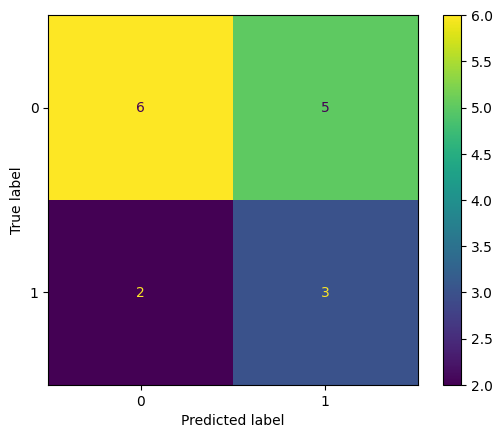

In [ ]:
disp = ConfusionMatrixDisplay(confusion_matrix=confusion_matrix(y_test, y_pred),
                              display_labels=clf.classes_)

disp.plot()

## visualizing the model

---



This is code from the guide as well. I modifiied it for this project

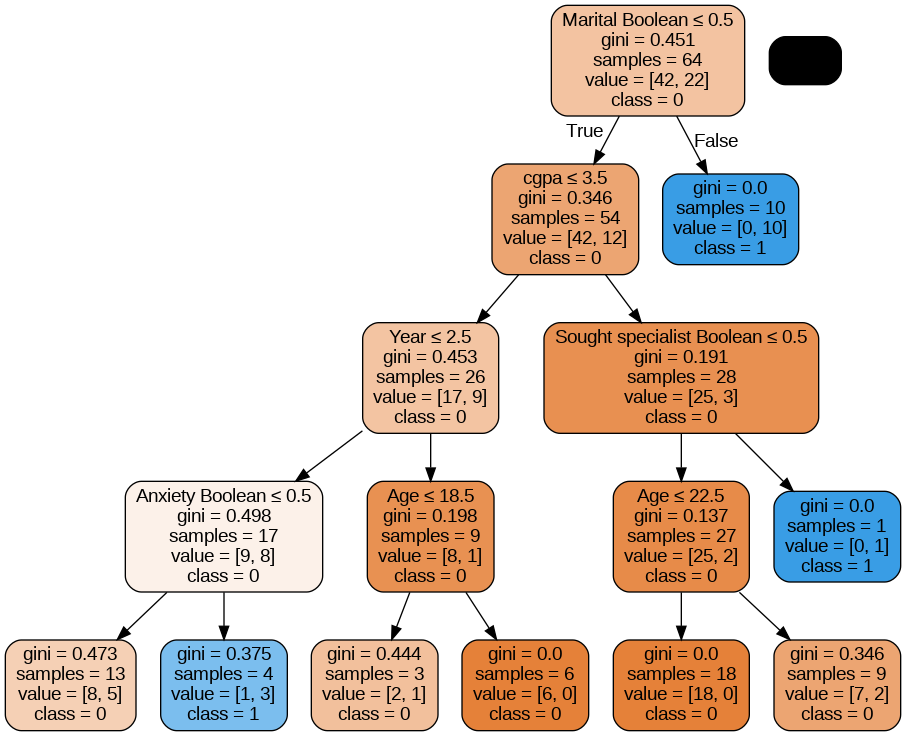

In [ ]:
from sklearn.tree import export_graphviz
from io import StringIO
from IPython.display import Image
import pydotplus

feature_cols = ['Age', 'gender Boolean', 'Year', 'Sought specialist Boolean', 'Panic Attack Boolean', 'Anxiety Boolean', 'Marital Boolean', 'cgpa']

best_classifier = grid_search.best_estimator_

dot_data = StringIO()
export_graphviz(best_classifier, out_file=dot_data,
                filled=True, rounded=True,
                special_characters=True,feature_names = feature_cols,class_names=['0','1'])
graph = pydotplus.graph_from_dot_data(dot_data.getvalue())
graph.write_png('depression.png')
Image(graph.create_png())

Understanding the decision tree model

# Interpretting and understanding the decision tree model
---

##Making a new decision tree with fewer features for better understandibility

Chose the features year of study, anxiety, gpa, and if they chose a specialist or not

In [ ]:
X = np.column_stack((year, panic_attack, anxiety, gpa, specialist))
y = train.column("Depression boolean")

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state =17, test_size= 0.2)

In [ ]:
# Create Decision Tree classifer object
clf = DecisionTreeClassifier()

# Train Decision Tree Classifer
clf = clf.fit(X_train,y_train)

#Predict the response for test dataset
y_pred = clf.predict(X_test)

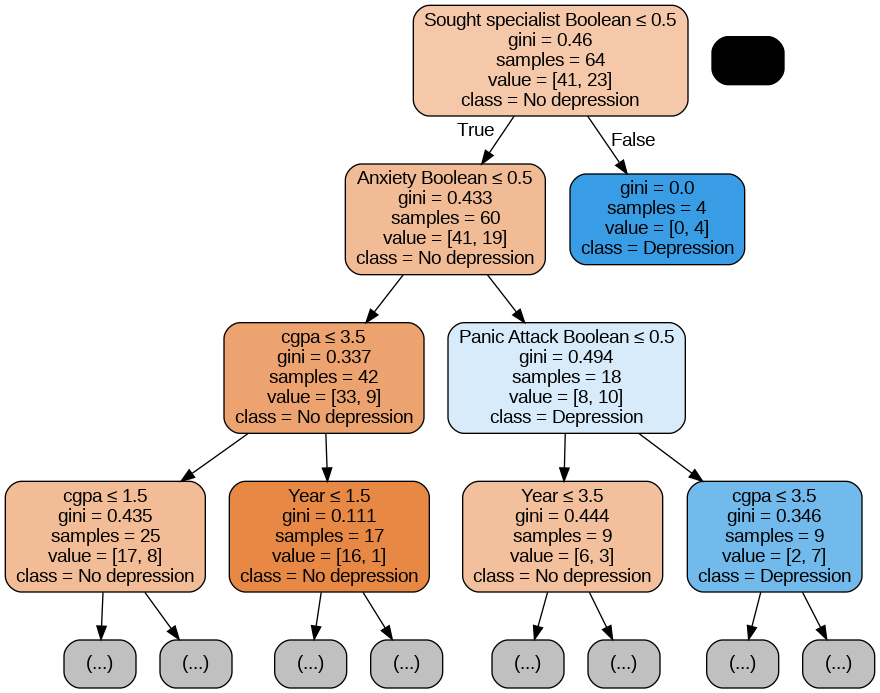

In [ ]:
from sklearn.tree import export_graphviz
from io import StringIO
from IPython.display import Image
import pydotplus

feature_cols = ['Year', 'Panic Attack Boolean' , 'Anxiety Boolean','cgpa',  'Sought specialist Boolean']

dot_data = StringIO()
export_graphviz(clf, out_file=dot_data,
                filled=True, rounded=True,
                special_characters=True,
                feature_names = feature_cols,class_names=['No depression','Depression'],
                max_depth=3
                )
graph = pydotplus.graph_from_dot_data(dot_data.getvalue())
graph.write_png('depression.png')
Image(graph.create_png())